# 02. Exploratory Data Analysis

This notebook performs a small EDA on the temporary dummy Component 1 output.

> **Important:** This is synthetic development data only.  

## Expected input
`data/processed/dummy_c1_output.csv`

## Columns
- review_id
- parent_asin
- timestamp
- review_text
- aspect
- sentiment_label
- sentiment_score
- confidence


In [16]:
import pandas as pd
import numpy as np
from pathlib import Path

WORKSPACE = Path.cwd()
if WORKSPACE.name == "notebooks":
    COMPONENT_ROOT = WORKSPACE.parent
elif (WORKSPACE / "data" / "processed").exists():
    COMPONENT_ROOT = WORKSPACE
else:
    COMPONENT_ROOT = WORKSPACE / "component_3"

INPUT = COMPONENT_ROOT / "data" / "processed" / "dummy_c1_output.csv"
FIGURE_DIR = COMPONENT_ROOT / "outputs" / "figures"
TABLE_DIR = COMPONENT_ROOT / "outputs" / "tables"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
TABLE_DIR.mkdir(parents=True, exist_ok=True)


## 1. Load the dataset


In [17]:
df = pd.read_csv(INPUT)

print("Dataset shape:", df.shape)
display(df.head())


Dataset shape: (4978, 8)


,review_id,parent_asin,timestamp,review_text,aspect,sentiment_label,sentiment_score,confidence
0,DUMMY_R002422,B00FFJ0HUE,2021-01-03T20:22:40,Performance is acceptable for basic use.,performance,neutral,0.1911,0.7555
1,DUMMY_R002455,B00FFJ0HUE,2021-01-04T21:54:07,Screen quality is sharp and easy to read. I no...,display,positive,0.6695,0.8049
2,DUMMY_R002515,B00FFJ0HUE,2021-01-08T20:54:08,Heat has not been a problem for me.,thermal,positive,0.4124,0.7215
3,DUMMY_R002385,B00FFJ0HUE,2021-01-09T05:39:37,The battery is acceptable but not outstanding....,battery,neutral,-0.1802,0.7241
4,DUMMY_R002456,B00FFJ0HUE,2021-01-13T08:20:50,Screen quality is average.,display,neutral,0.1344,0.7255


## 2. Basic dataset information


In [18]:
print("Columns:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isna().sum())

print("\nDuplicate review IDs:", df["review_id"].duplicated().sum())


Columns:
['review_id', 'parent_asin', 'timestamp', 'review_text', 'aspect', 'sentiment_label', 'sentiment_score', 'confidence']

Data types:
review_id              str
parent_asin            str
timestamp              str
review_text            str
aspect                 str
sentiment_label        str
sentiment_score    float64
confidence         float64
dtype: object

Missing values:
review_id          0
parent_asin        0
timestamp          0
review_text        0
aspect             0
sentiment_label    0
sentiment_score    0
confidence         0
dtype: int64

Duplicate review IDs: 0


## 3. Validate and prepare timestamp information


In [19]:
df["timestamp"] = pd.to_datetime(
    df["timestamp"],
    utc=True,
    errors="coerce"
)

print("Invalid timestamps:", df["timestamp"].isna().sum())

df = df.dropna(subset=["timestamp"]).copy()

df["quarter"] = (
    df["timestamp"]
    .dt.tz_localize(None)
    .dt.to_period("Q")
    .astype(str)
)

print("Date range:")
print("Start:", df["timestamp"].min())
print("End  :", df["timestamp"].max())

print("\nNumber of quarters:", df["quarter"].nunique())


Invalid timestamps: 0
Date range:
Start: 2021-01-01 00:16:11+00:00
End  : 2023-09-30 15:26:55+00:00

Number of quarters: 11


## 4. Dataset overview


In [20]:
overview = pd.DataFrame({
    "Metric": [
        "Reviews",
        "Products",
        "Aspects",
        "Quarters",
        "Positive reviews",
        "Neutral reviews",
        "Negative reviews",
    ],
    "Value": [
        len(df),
        df["parent_asin"].nunique(),
        df["aspect"].nunique(),
        df["quarter"].nunique(),
        (df["sentiment_label"] == "positive").sum(),
        (df["sentiment_label"] == "neutral").sum(),
        (df["sentiment_label"] == "negative").sum(),
    ]
})

display(overview)

overview.to_csv(
    TABLE_DIR / "dummy_eda_overview.csv",
    index=False
)


,Metric,Value
0,Reviews,4978
1,Products,10
2,Aspects,6
3,Quarters,11
4,Positive reviews,3110
5,Neutral reviews,1514
6,Negative reviews,354


## 5. Reviews per product


,parent_asin,review_count
9,B0C2ZMJW53,607
2,B00L49X8E6,604
8,B07GM2J11Q,591
6,B01K1IO3QW,580
3,B00NOSVK54,574
5,B019BX7F86,570
4,B00TW47DSW,568
7,B01MPXRXR0,546
1,B00KB7O49K,172
0,B00FFJ0HUE,166


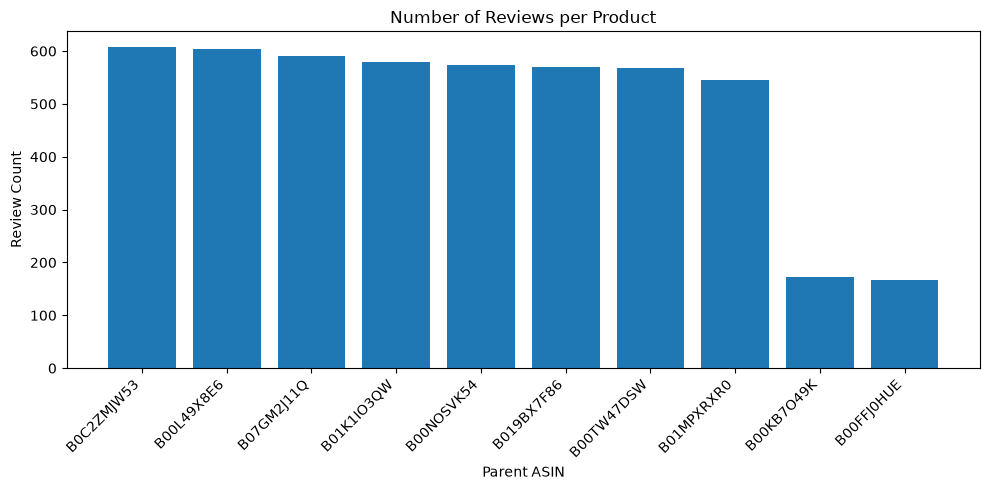

In [21]:
product_counts = (
    df.groupby("parent_asin")
      .size()
      .reset_index(name="review_count")
      .sort_values("review_count", ascending=False)
)

display(product_counts)

plt.figure(figsize=(10, 5))
plt.bar(
    product_counts["parent_asin"],
    product_counts["review_count"]
)
plt.title("Number of Reviews per Product")
plt.xlabel("Parent ASIN")
plt.ylabel("Review Count")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "dummy_reviews_per_product.png",
    dpi=180,
    bbox_inches="tight"
)

plt.show()


## 6. Aspect distribution


,aspect,review_count
0,battery,1015
1,display,1014
2,thermal,987
3,performance,984
4,keyboard,506
5,camera,472


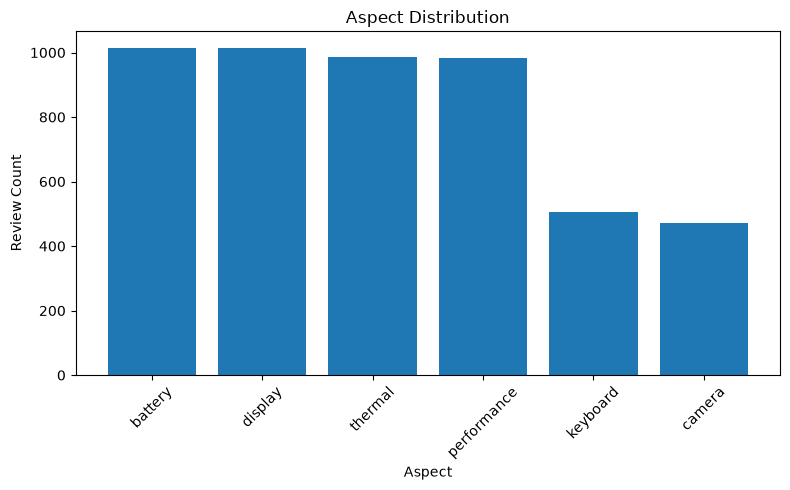

In [22]:
aspect_counts = (
    df["aspect"]
    .value_counts()
    .rename_axis("aspect")
    .reset_index(name="review_count")
)

display(aspect_counts)

plt.figure(figsize=(8, 5))
plt.bar(
    aspect_counts["aspect"],
    aspect_counts["review_count"]
)
plt.title("Aspect Distribution")
plt.xlabel("Aspect")
plt.ylabel("Review Count")
plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "dummy_aspect_distribution.png",
    dpi=180,
    bbox_inches="tight"
)

plt.show()


## 7. Sentiment distribution


,sentiment_label,review_count
0,positive,3110
1,neutral,1514
2,negative,354


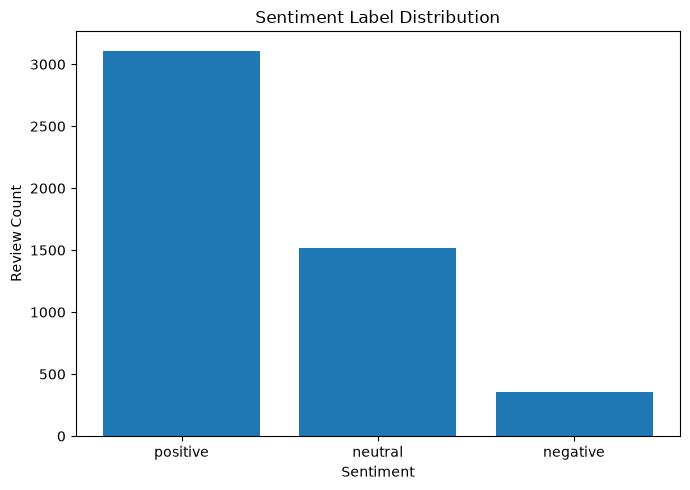

In [23]:
sentiment_order = ["positive", "neutral", "negative"]

sentiment_counts = (
    df["sentiment_label"]
    .value_counts()
    .reindex(sentiment_order, fill_value=0)
)

display(
    sentiment_counts
    .rename("review_count")
    .reset_index()
    .rename(columns={"index": "sentiment_label"})
)

plt.figure(figsize=(7, 5))
plt.bar(
    sentiment_counts.index,
    sentiment_counts.values
)
plt.title("Sentiment Label Distribution")
plt.xlabel("Sentiment")
plt.ylabel("Review Count")
plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "dummy_sentiment_distribution.png",
    dpi=180,
    bbox_inches="tight"
)

plt.show()


## 8. Sentiment score and confidence summary


In [24]:
score_summary = df[
    ["sentiment_score", "confidence"]
].describe().round(4)

display(score_summary)

print(
    "Mean sentiment score:",
    round(df["sentiment_score"].mean(), 4)
)

print(
    "Mean confidence:",
    round(df["confidence"].mean(), 4)
)


,sentiment_score,confidence
count,4978.0000,4978.0000
mean,0.3074,0.7628
std,0.3426,0.0703
min,-0.8883,0.6000
25%,0.0838,0.7111
50%,0.3113,0.7548
75%,0.5404,0.8097
max,1.0000,0.9900


Mean sentiment score: 0.3074
Mean confidence: 0.7628


## 9. Reviews by quarter


,quarter,review_count
0,2021Q1,480
1,2021Q2,429
2,2021Q3,473
3,2021Q4,485
4,2022Q1,433
5,2022Q2,441
6,2022Q3,456
7,2022Q4,425
8,2023Q1,456
9,2023Q2,417


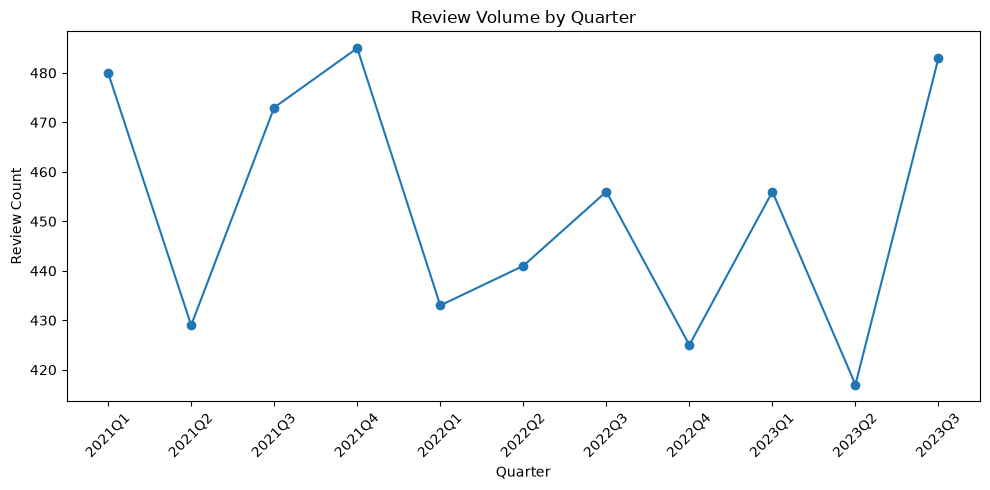

In [25]:
quarter_counts = (
    df.groupby("quarter")
      .size()
      .reset_index(name="review_count")
)

display(quarter_counts)

plt.figure(figsize=(10, 5))
plt.plot(
    quarter_counts["quarter"],
    quarter_counts["review_count"],
    marker="o"
)
plt.title("Review Volume by Quarter")
plt.xlabel("Quarter")
plt.ylabel("Review Count")
plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "dummy_reviews_by_quarter.png",
    dpi=180,
    bbox_inches="tight"
)

plt.show()


## 10. Product × Aspect coverage


In [26]:
product_aspect_counts = (
    df.groupby(
        ["parent_asin", "aspect"]
    )
    .size()
    .reset_index(name="review_count")
)

display(
    product_aspect_counts
    .sort_values(
        "review_count",
        ascending=False
    )
    .head(30)
)

product_aspect_counts.to_csv(
    TABLE_DIR / "dummy_product_aspect_counts.csv",
    index=False
)


,parent_asin,aspect,review_count
10,B00L49X8E6,battery,129
43,B07GM2J11Q,performance,129
47,B0C2ZMJW53,keyboard,129
48,B0C2ZMJW53,performance,128
14,B00L49X8E6,thermal,127
46,B0C2ZMJW53,display,124
19,B00NOSVK54,thermal,123
20,B00TW47DSW,battery,122
30,B01K1IO3QW,battery,122
22,B00TW47DSW,display,121


## 11. Product × Aspect × Quarter support

This check is useful for Component 3 because sparse Product × Aspect × Quarter groups may produce unstable raw sentiment averages.


In [27]:
paq_support = (
    df.groupby(
        ["parent_asin", "aspect", "quarter"]
    )
    .size()
    .reset_index(name="review_count")
)

display(
    paq_support
    .sort_values("review_count")
    .head(30)
)

print(
    "Minimum PAQ support:",
    paq_support["review_count"].min()
)

print(
    "Median PAQ support:",
    paq_support["review_count"].median()
)

print(
    "Maximum PAQ support:",
    paq_support["review_count"].max()
)

print(
    "PAQ groups with fewer than 5 reviews:",
    (paq_support["review_count"] < 5).sum()
)

paq_support.to_csv(
    TABLE_DIR / "dummy_paq_support.csv",
    index=False
)


,parent_asin,aspect,quarter,review_count
59,B00KB7O49K,battery,2022Q1,1
75,B00KB7O49K,camera,2023Q2,1
73,B00KB7O49K,camera,2022Q4,1
64,B00KB7O49K,battery,2023Q2,1
97,B00KB7O49K,performance,2023Q2,1
106,B00KB7O49K,thermal,2022Q4,1
84,B00KB7O49K,display,2022Q4,1
9,B00FFJ0HUE,battery,2023Q2,1
15,B00FFJ0HUE,display,2022Q1,1
12,B00FFJ0HUE,display,2021Q2,1


Minimum PAQ support: 1
Median PAQ support: 10.0
Maximum PAQ support: 14
PAQ groups with fewer than 5 reviews: 88


## 12. Negative reviews available for complaint analysis


In [28]:
negative_reviews = df[
    df["sentiment_label"] == "negative"
].copy()

negative_summary = (
    negative_reviews
    .groupby(["aspect", "quarter"])
    .size()
    .reset_index(name="negative_review_count")
)

print(
    "Total negative reviews:",
    len(negative_reviews)
)

display(
    negative_summary.head(30)
)

negative_summary.to_csv(
    TABLE_DIR / "dummy_negative_reviews_by_aspect_quarter.csv",
    index=False
)


Total negative reviews: 354


,aspect,quarter,negative_review_count
0,battery,2021Q1,6
1,battery,2021Q2,3
2,battery,2021Q3,7
3,battery,2021Q4,7
4,battery,2022Q1,4
5,battery,2022Q2,4
6,battery,2022Q3,6
7,battery,2022Q4,12
8,battery,2023Q1,8
9,battery,2023Q2,9


# EDA Summary

This dummy dataset is suitable for development if:

- all required C1 → C3 fields are available;
- timestamps can be converted into quarters;
- multiple products and aspects are present;
- Product × Aspect × Quarter groups can be created;
- some low-support groups exist for testing Bayesian smoothing;
- negative reviews are available for later SBERT + BERTopic complaint analysis.

